In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from google.colab import files
uploaded = files.upload()

df = pd.read_csv("AirPassengers.csv")

df["Month"] = pd.to_datetime(df["Month"])
df = df.set_index("Month").sort_index()

# Specify monthly frequency
df = df.asfreq("MS")

ts = df["#Passengers"]

Saving AirPassengers.csv to AirPassengers.csv


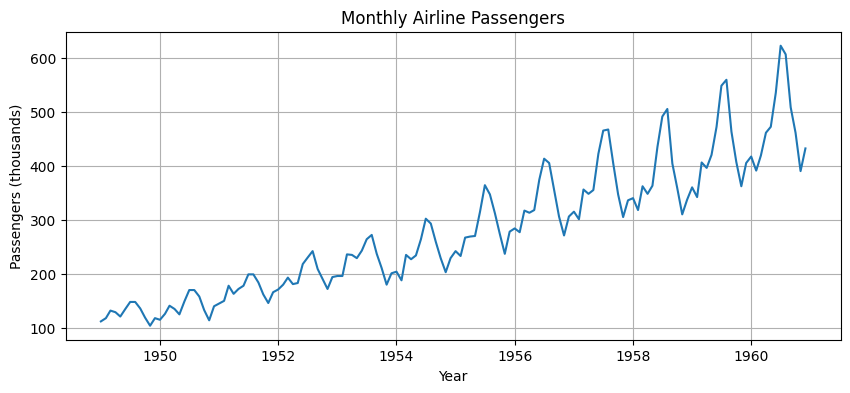

In [ ]:
plt.figure(figsize=(10, 4))

plt.plot(ts)

plt.title("Monthly Airline Passengers")
plt.xlabel("Year")
plt.ylabel("Passengers (thousands)")
plt.grid(True)

plt.show()

In [ ]:
size = int(len(ts) * 0.7)

train = ts.iloc[:size]
test = ts.iloc[size:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

Training observations: 100
Testing observations: 44


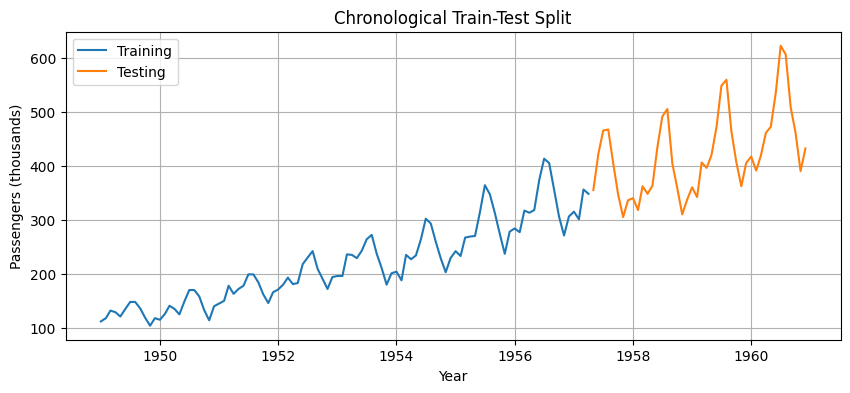

In [ ]:
plt.figure(figsize=(10, 4))

plt.plot(train, label="Training")
plt.plot(test, label="Testing")

plt.title("Chronological Train-Test Split")
plt.xlabel("Year")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
log_train = np.log(train)
log_test = np.log(test)


In [ ]:
model = ARIMA(log_train, order=(12,1,2))

model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:            #Passengers   No. Observations:                  100
Model:                ARIMA(12, 1, 2)   Log Likelihood                 162.018
Date:                Tue, 10 Nov 2026   AIC                           -294.035
Time:                        01:56:22   BIC                           -255.109
Sample:                    01-01-1949   HQIC                          -278.286
                         - 04-01-1957                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1156      0.115      1.004      0.315      -0.110       0.341
ar.L2         -0.0708      0.096     -0.738      0.461      -0.259       0.117
ar.L3          0.0139      0.062      0.223      0.8

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [ ]:
forecast_log = model_fit.forecast(steps=len(test))

forecast = np.exp(forecast_log)

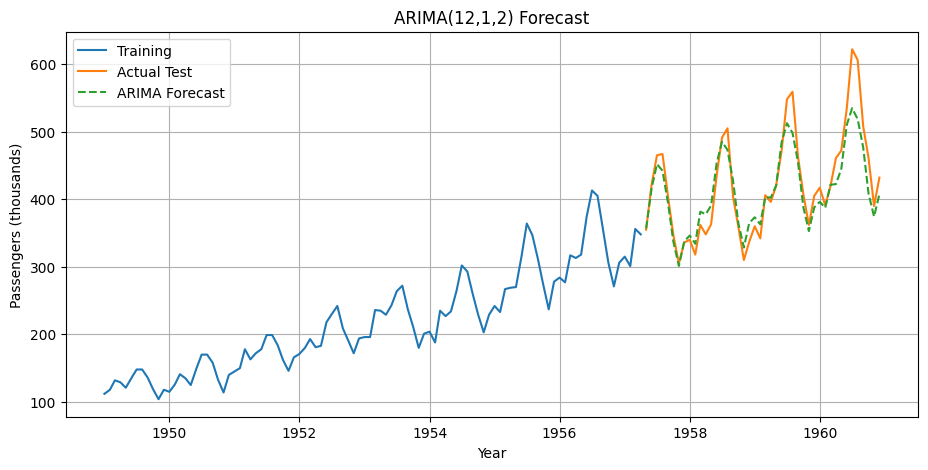

In [ ]:
plt.figure(figsize=(11, 5))

plt.plot(train, label="Training")
plt.plot(test, label="Actual Test")
plt.plot(forecast, label="ARIMA Forecast",
         linestyle="--")

plt.title("ARIMA(12,1,2) Forecast")
plt.xlabel("Year")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
rmse = np.sqrt(np.mean(
    (test.values - forecast.values) ** 2
))

mae = np.mean(
    np.abs(test.values - forecast.values)
)

print("ARIMA RMSE:", rmse)
print("ARIMA MAE:", mae)

ARIMA RMSE: 28.685208810738956
ARIMA MAE: 20.97177061275422
